In [1]:
import os
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

In [2]:
os.environ["TORCH_HOME"] = "D:/torch_cache"

In [3]:
SEED = 42
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Computation Device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


In [4]:
# Project paths 

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR      = PROJECT_ROOT / "data" / "raw" / "images"
SPLITS_DIR   = PROJECT_ROOT / "data" / "splits"
REPORTS_DIR  = PROJECT_ROOT / "reports"
EMB_DIR      = PROJECT_ROOT / "artifacts" / "embeddings"
META_DIR     = PROJECT_ROOT / "artifacts" / "metadata"
MODELS_DIR   = PROJECT_ROOT / "models"

In [5]:
for d in [EMB_DIR, META_DIR, MODELS_DIR, REPORTS_DIR / "classification", REPORTS_DIR / "retrieval", REPORTS_DIR / "visualizations"]:
    d.mkdir(parents=True, exist_ok=True)

In [6]:
train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df   = pd.read_csv(SPLITS_DIR / "val.csv")
test_df  = pd.read_csv(SPLITS_DIR / "test.csv")

In [7]:
with open(SPLITS_DIR / "label_mapping.json", "r") as f:
    mapping = json.load(f)
label_to_idx = mapping["label_to_idx"]
idx_to_label = {int(k): v for k, v in mapping["idx_to_label"].items()}
NUM_CLASSES  = len(label_to_idx)

print(f"Loaded Splits -> Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,} | Classes (C): {NUM_CLASSES}")

Loaded Splits -> Train: 20,906 | Val: 4,480 | Test: 4,481 | Classes (C): 51


In [8]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [9]:
class FashionRetailDataset(Dataset):
    def __init__(self, manifest_df, img_dir, transform=None):
        self.df = manifest_df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.img_dir / f"{row['id']}.jpg"
        with Image.open(img_path) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(row["label_idx"]), str(row["id"])
        
EXP_CSV_PATH = REPORTS_DIR / "experiment_comparison.csv"
EXP_COLUMNS = [
    "experiment_id", "checkpoint", "split", "accuracy", "macro_f1",
    "precision_at_5", "recall_at_5", "map", "query_latency_ms", "index_size_mb", "notes"
]

In [10]:
def log_experiment_row(row_dict):
    rows = []
    if EXP_CSV_PATH.exists():
        df_existing = pd.read_csv(EXP_CSV_PATH)
        df_existing = df_existing[~((df_existing["experiment_id"] == row_dict["experiment_id"]) & (df_existing["split"] == row_dict["split"]))]
        rows = df_existing.to_dict("records")
    rows.append(row_dict)
    pd.DataFrame(rows, columns=EXP_COLUMNS).to_csv(EXP_CSV_PATH, index=False)

# pretrained resnet18 model embedding extractor


In [16]:
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

def get_pretrained_feature_extractor():
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)
    model.fc = nn.Identity()  # Output 512-D pooled vector
    model.eval()
    return model.to(DEVICE)

d:\dl_gpu_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
def load_single_image(args):
    img_path, label, item_id = args
    with Image.open(img_path) as img:
        tensor = eval_transform(img.convert("RGB"))
    return tensor, label, item_id

In [19]:
@torch.no_grad()
def extract_embeddings_fast(manifest_df, model, desc="Extracting", batch_size=256):
    model.eval()
    records = [
        (IMG_DIR / f"{row['id']}.jpg", int(row["label_idx"]), str(row["id"]))
        for _, row in manifest_df.iterrows()
    ]
    all_embeddings, all_labels, all_ids = [], [], []

    with ThreadPoolExecutor(max_workers=8) as pool:
        for start in tqdm(range(0, len(records), batch_size), desc=desc):
            batch_records = records[start : start + batch_size]
            batch_loaded = list(pool.map(load_single_image, batch_records))

            imgs = torch.stack([b[0] for b in batch_loaded]).to(DEVICE, non_blocking=True)
            labels = np.array([b[1] for b in batch_loaded], dtype=np.int64)
            ids = [b[2] for b in batch_loaded]

            # Use RTX 3050 FP16 Tensor Cores for 2x faster inference
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                feats = model(imgs).float()
            feats_norm = nn.functional.normalize(feats, p=2, dim=1)

            all_embeddings.append(feats_norm.cpu().numpy())
            all_labels.append(labels)
            all_ids.extend(ids)

    return np.vstack(all_embeddings).astype(np.float32), np.concatenate(all_labels), np.array(all_ids)

pretrained_extractor = get_pretrained_feature_extractor()
print("Fast extractor ready on:", next(pretrained_extractor.parameters()).device)


Fast extractor ready on: cuda:0


In [20]:
val_emb_e1,  val_labels_e1,  val_ids_e1  = extract_embeddings_fast(val_df,  pretrained_extractor, desc="Val Set (4,480 imgs)")
test_emb_e1, test_labels_e1, test_ids_e1 = extract_embeddings_fast(test_df, pretrained_extractor, desc="Test Set (4,481 imgs)")

np.save(EMB_DIR / "e1_pretrained_val_embeddings.npy",  val_emb_e1)
np.save(EMB_DIR / "e1_pretrained_test_embeddings.npy", test_emb_e1)
print("Saved Val & Test embeddings! Shapes:", val_emb_e1.shape, test_emb_e1.shape)

Test Set (4,481 imgs): 100%|██████████| 18/18 [00:09<00:00,  1.98it/s]

Saved Val & Test embeddings! Shapes: (4480, 512) (4481, 512)


In [21]:
cat_emb_e1, cat_labels_e1, cat_ids_e1 = extract_embeddings_fast(train_df, pretrained_extractor, desc="Train Catalog (20,906 imgs)")

np.save(EMB_DIR / "e1_pretrained_catalog_embeddings.npy", cat_emb_e1)
train_df.to_csv(META_DIR / "product_metadata.csv", index=False)
print("Saved Train Catalog embeddings! Shape:", cat_emb_e1.shape)

Train Catalog (20,906 imgs): 100%|██████████| 82/82 [00:36<00:00,  2.27it/s]


Saved Train Catalog embeddings! Shape: (20906, 512)


In [ ]:
def evaluate_retrieval_numpy(query_emb, query_labels, gallery_emb, gallery_labels, num_classes, k=5):
    t_start = time.perf_counter()
    
    sim_matrix = np.matmul(query_emb, gallery_emb.T)

    
    top_k_indices = np.argpartition(-sim_matrix, kth=k, axis=1)[:, :k] # top k similarity for each query 
    row_idx = np.arange(len(query_emb))[:, None]
    sorted_order = np.argsort(-sim_matrix[row_idx, top_k_indices], axis=1)
    top_k_sorted = top_k_indices[row_idx, sorted_order]

    elapsed_ms = (time.perf_counter() - t_start) * 1000.0
    avg_latency_ms = elapsed_ms / len(query_emb)

    
    retrieved_labels = gallery_labels[top_k_sorted]
    relevant_mask = (retrieved_labels == query_labels[:, None]).astype(np.float32)

    
    precision_at_k = float(np.mean(np.sum(relevant_mask, axis=1) / k))


    gallery_class_counts = np.bincount(gallery_labels, minlength=num_classes)
    total_rel_per_query = np.maximum(gallery_class_counts[query_labels], 1)
    recall_at_k = float(np.mean(np.sum(relevant_mask, axis=1) / total_rel_per_query))

    
    precisions_at_i = np.cumsum(relevant_mask, axis=1) / np.arange(1, k + 1)[None, :]
    ap_per_query = np.sum(precisions_at_i * relevant_mask, axis=1) / np.minimum(total_rel_per_query, k)
    map_at_k = float(np.mean(ap_per_query))

    return {
        "precision_at_5": round(precision_at_k, 4),
        "recall_at_5": round(recall_at_k, 4),
        "map_at_5": round(map_at_k, 4),
        "avg_query_latency_ms": round(avg_latency_ms, 4),
        "index_size_mb": round(gallery_emb.nbytes / (1024 * 1024), 2),
    }, top_k_sorted

e1_metrics, e1_top5_indices = evaluate_retrieval_numpy(
    test_emb_e1, test_labels_e1, cat_emb_e1, cat_labels_e1, num_classes=NUM_CLASSES, k=5
)

with open(REPORTS_DIR / "retrieval" / "pretrained_metrics.json", "w") as f:
    json.dump(e1_metrics, f, indent=2)

log_experiment_row({
    "experiment_id": "E1_pretrained_resnet18_retrieval",
    "checkpoint": "ImageNet1K_ResNet18_Default",
    "split": "test",
    "accuracy": "N/A",
    "macro_f1": "N/A",
    "precision_at_5": e1_metrics["precision_at_5"],
    "recall_at_5": e1_metrics["recall_at_5"],
    "map": e1_metrics["map_at_5"],
    "query_latency_ms": e1_metrics["avg_query_latency_ms"],
    "index_size_mb": e1_metrics["index_size_mb"],
    "notes": "Off-the-shelf 512-D ImageNet features before retail training (Cosine similarity)."
})

print("E1: PRETRAINED RESNET-18 RETRIEVAL RESULTS")
print(json.dumps(e1_metrics, indent=2))

E1: PRETRAINED RESNET-18 RETRIEVAL RESULTS
{
  "precision_at_5": 0.7654,
  "recall_at_5": 0.0084,
  "map_at_5": 0.7226,
  "avg_query_latency_ms": 0.2116,
  "index_size_mb": 40.83
}


In [ ]:
class ResNet18RetailClassifier(nn.Module):
    def __init__(self, num_classes=51, dropout_p=0.2):
        super().__init__()
        # Load ImageNet-pretrained ResNet-18
        base_model = resnet18(weights=ResNet18_Weights.DEFAULT)
        
        
        for param in base_model.parameters():
            param.requires_grad = False
            
        
        self.backbone = nn.Sequential(*list(base_model.children())[:-1], nn.Flatten(start_dim=1))
        self.classifier_head = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(in_features=512, out_features=num_classes)
        )

    def extract_features(self, x):
        """Extracts L2-normalized 512-D visual embedding vector."""
        feats = self.backbone(x)
        return nn.functional.normalize(feats, p=2, dim=1)

    def forward(self, x):
        """Full forward pass: Image [B, 3, 224, 224] -> 512-D normalized embedding -> [B, 51] class logits."""
        feats = self.extract_features(x)
        logits = self.classifier_head(feats)
        return logits, feats

In [ ]:
model_e2 = ResNet18RetailClassifier(num_classes=NUM_CLASSES, dropout_p=0.2).to(DEVICE)

total_params     = sum(p.numel() for p in model_e2.parameters())
trainable_params = sum(p.numel() for p in model_e2.parameters() if p.requires_grad)
frozen_params    = total_params - trainable_params

print("=== E2 ARCHITECTURE & PARAMETER SUMMARY ===")
print(f"Total Parameters     : {total_params:,}")
print(f"Frozen Backbone      : {frozen_params:,} ({100*frozen_params/total_params:.2f}%)")
print(f"Trainable Head (512->51): {trainable_params:,} ({100*trainable_params/total_params:.2f}%)")

=== E2 ARCHITECTURE & PARAMETER SUMMARY ===
Total Parameters     : 11,202,675
Frozen Backbone      : 11,176,512 (99.77%)
Trainable Head (512->51): 26,163 (0.23%)


In [25]:
dummy_x = torch.randn(4, 3, 224, 224, device=DEVICE)
with torch.no_grad():
    dummy_logits, dummy_feats = model_e2(dummy_x)
print(f"\nTensor Flow Trace:")
print(f"  Input Image Batch : {tuple(dummy_x.shape)}")
print(f"  Pooled Embedding  : {tuple(dummy_feats.shape)}")
print(f"  Output Logits     : {tuple(dummy_logits.shape)}")


Tensor Flow Trace:
  Input Image Batch : (4, 3, 224, 224)
  Pooled Embedding  : (4, 512)
  Output Logits     : (4, 51)


In [ ]:
from torch.utils.data import TensorDataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

seed_everything(SEED)


train_feat_ds = TensorDataset(torch.from_numpy(cat_emb_e1), torch.from_numpy(cat_labels_e1).long())
val_feat_ds   = TensorDataset(torch.from_numpy(val_emb_e1), torch.from_numpy(val_labels_e1).long())

train_feat_loader = DataLoader(train_feat_ds, batch_size=256, shuffle=True)
val_feat_loader   = DataLoader(val_feat_ds,   batch_size=256, shuffle=False)

In [27]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_e2.classifier_head.parameters(), lr=1e-2, weight_decay=1e-4)
EPOCHS = 25
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-4)

history = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
best_val_f1 = -1.0
best_head_state = None

In [ ]:
print(f"Training E2 Frozen-Backbone Retail Classifier Head for {EPOCHS} epochs...")
for epoch in range(1, EPOCHS + 1):
    
    model_e2.classifier_head.train()
    train_loss_sum, train_preds, train_targets = 0.0, [], []
    for feats_b, labels_b in train_feat_loader:
        feats_b, labels_b = feats_b.to(DEVICE), labels_b.to(DEVICE)
        optimizer.zero_grad()
        logits = model_e2.classifier_head(feats_b)
        loss = criterion(logits, labels_b)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(labels_b)
        train_preds.append(logits.argmax(dim=1).cpu().numpy())
        train_targets.append(labels_b.cpu().numpy())

    scheduler.step()
    train_loss = train_loss_sum / len(train_feat_ds)
    train_acc  = accuracy_score(np.concatenate(train_targets), np.concatenate(train_preds))

    model_e2.classifier_head.eval()
    val_loss_sum, val_preds, val_targets = 0.0, [], []
    with torch.no_grad():
        for feats_b, labels_b in val_feat_loader:
            feats_b, labels_b = feats_b.to(DEVICE), labels_b.to(DEVICE)
            logits = model_e2.classifier_head(feats_b)
            loss = criterion(logits, labels_b)
            val_loss_sum += loss.item() * len(labels_b)
            val_preds.append(logits.argmax(dim=1).cpu().numpy())
            val_targets.append(labels_b.cpu().numpy())

    val_loss = val_loss_sum / len(val_feat_ds)
    val_preds_arr   = np.concatenate(val_preds)
    val_targets_arr = np.concatenate(val_targets)
    val_acc  = accuracy_score(val_targets_arr, val_preds_arr)
    val_f1   = f1_score(val_targets_arr, val_preds_arr, average="macro", zero_division=0)

    history["epoch"].append(epoch)
    history["train_loss"].append(round(train_loss, 4))
    history["val_loss"].append(round(val_loss, 4))
    history["train_acc"].append(round(train_acc, 4))
    history["val_acc"].append(round(val_acc, 4))
    history["val_macro_f1"].append(round(val_f1, 4))

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_head_state = {k: v.cpu().clone() for k, v in model_e2.classifier_head.state_dict().items()}

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val Macro-F1: {val_f1*100:.2f}%")
        

Training E2 Frozen-Backbone Retail Classifier Head for 25 epochs...
Epoch 01/25 | Train Loss: 2.3385 (Acc: 39.53%) | Val Loss: 1.5808 | Val Acc: 62.03% | Val Macro-F1: 33.68%
Epoch 05/25 | Train Loss: 0.7764 (Acc: 77.70%) | Val Loss: 0.7499 | Val Acc: 77.54% | Val Macro-F1: 63.40%
Epoch 10/25 | Train Loss: 0.6163 (Acc: 80.92%) | Val Loss: 0.6175 | Val Acc: 80.04% | Val Macro-F1: 70.72%
Epoch 15/25 | Train Loss: 0.5673 (Acc: 82.29%) | Val Loss: 0.5735 | Val Acc: 81.61% | Val Macro-F1: 73.37%
Epoch 20/25 | Train Loss: 0.5439 (Acc: 82.67%) | Val Loss: 0.5586 | Val Acc: 82.08% | Val Macro-F1: 74.63%
Epoch 25/25 | Train Loss: 0.5405 (Acc: 82.73%) | Val Loss: 0.5556 | Val Acc: 82.23% | Val Macro-F1: 75.48%


In [29]:
model_e2.classifier_head.load_state_dict({k: v.to(DEVICE) for k, v in best_head_state.items()})
torch.save({
    "model_state_dict": model_e2.state_dict(),
    "classifier_head_state_dict": best_head_state,
    "num_classes": NUM_CLASSES,
    "best_val_macro_f1": round(float(best_val_f1), 4),
    "seed": SEED,
}, MODELS_DIR / "e2_frozen_resnet18.pth")
pd.DataFrame(history).to_csv(REPORTS_DIR / "classification" / "e2_training_history.csv", index=False)

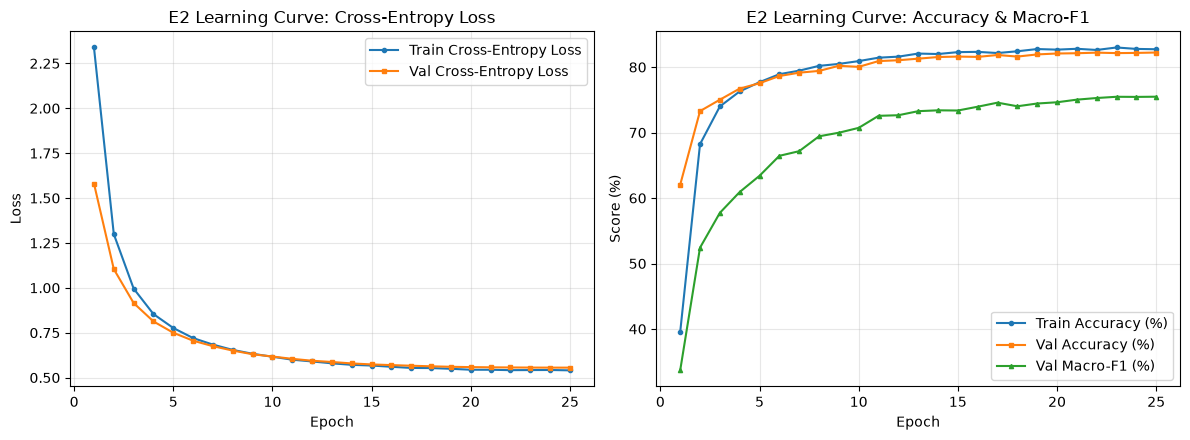

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history["epoch"], history["train_loss"], label="Train Cross-Entropy Loss", marker="o", markersize=3)
axes[0].plot(history["epoch"], history["val_loss"], label="Val Cross-Entropy Loss", marker="s", markersize=3)
axes[0].set_title("E2 Learning Curve: Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["epoch"], [x*100 for x in history["train_acc"]], label="Train Accuracy (%)", marker="o", markersize=3)
axes[1].plot(history["epoch"], [x*100 for x in history["val_acc"]], label="Val Accuracy (%)", marker="s", markersize=3)
axes[1].plot(history["epoch"], [x*100 for x in history["val_macro_f1"]], label="Val Macro-F1 (%)", marker="^", markersize=3)
axes[1].set_title("E2 Learning Curve: Accuracy & Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "classification" / "e2_learning_curves.png", dpi=150)
plt.show()

In [31]:
model_e2.eval()
with torch.no_grad():
    test_feats_tensor = torch.from_numpy(test_emb_e1).to(DEVICE)
    test_logits = model_e2.classifier_head(test_feats_tensor)
    test_probs  = torch.softmax(test_logits, dim=1).cpu().numpy()
    test_preds  = test_logits.argmax(dim=1).cpu().numpy()

    cat_feats_tensor = torch.from_numpy(cat_emb_e1).to(DEVICE)
    cat_logits = model_e2.classifier_head(cat_feats_tensor)
    cat_probs  = torch.softmax(cat_logits, dim=1).cpu().numpy()

In [32]:
e2_test_acc = accuracy_score(test_labels_e1, test_preds)
e2_test_f1  = f1_score(test_labels_e1, test_preds, average="macro", zero_division=0)
e2_top3_acc = np.mean([y in np.argsort(-p)[:3] for y, p in zip(test_labels_e1, test_probs)])

print("E2: FROZEN-BACKBONE CLASSIFIER TEST RESULTS")
print(f"E0 Majority Baseline -> Test Accuracy: {19.06:.2f}% | Test Macro-F1: {0.63:.2f}%")
print(f"E2 Trained Head      -> Test Accuracy: {e2_test_acc*100:.2f}% | Test Macro-F1: {e2_test_f1*100:.2f}% | Top-3 Accuracy: {e2_top3_acc*100:.2f}%")

E2: FROZEN-BACKBONE CLASSIFIER TEST RESULTS
E0 Majority Baseline -> Test Accuracy: 19.06% | Test Macro-F1: 0.63%
E2 Trained Head      -> Test Accuracy: 81.75% | Test Macro-F1: 74.67% | Top-3 Accuracy: 96.25%


In [33]:
target_names = [idx_to_label[i] for i in range(NUM_CLASSES)]
cls_report_dict = classification_report(test_labels_e1, test_preds, target_names=target_names, output_dict=True, zero_division=0)
pd.DataFrame(cls_report_dict).transpose().to_csv(REPORTS_DIR / "classification" / "e2_per_class_metrics.csv")

In [34]:
top15_label_indices = pd.Series(test_labels_e1).value_counts().head(15).index.tolist()
top15_names = [idx_to_label[i] for i in top15_label_indices]
cm_top15 = confusion_matrix(test_labels_e1, test_preds, labels=top15_label_indices)

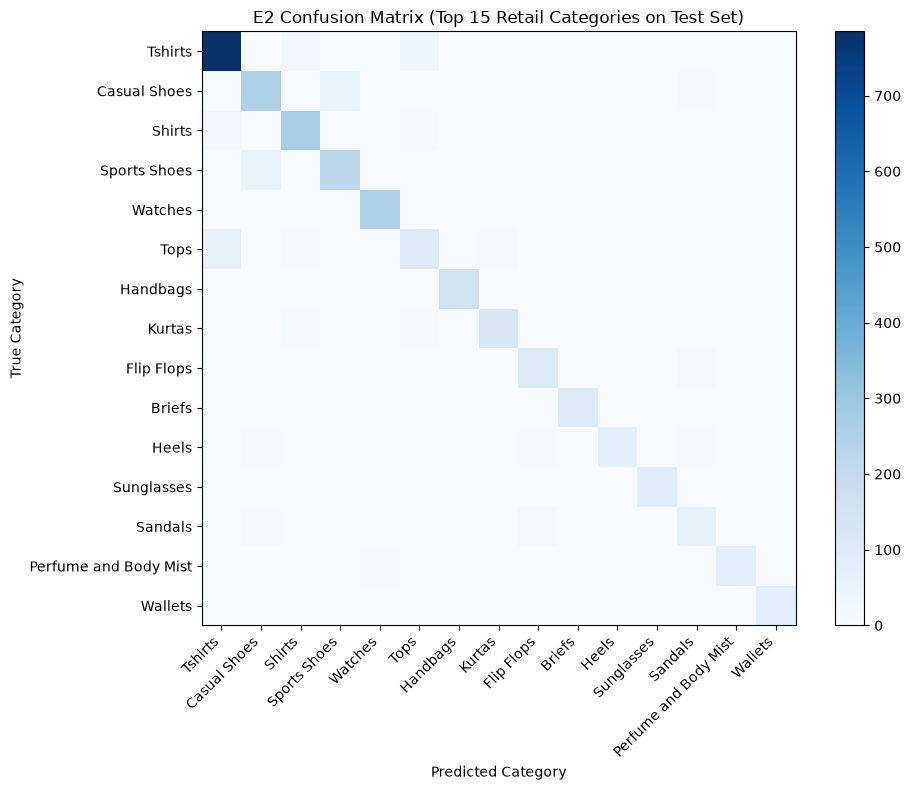

In [35]:
plt.figure(figsize=(10, 8))
plt.imshow(cm_top15, interpolation="nearest", cmap="Blues")
plt.title("E2 Confusion Matrix (Top 15 Retail Categories on Test Set)")
plt.colorbar()
tick_marks = np.arange(len(top15_names))
plt.xticks(tick_marks, top15_names, rotation=45, ha="right")
plt.yticks(tick_marks, top15_names)
plt.ylabel("True Category")
plt.xlabel("Predicted Category")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "classification" / "confusion_matrix_top15.png", dpi=150)
plt.show()

In [36]:
t_start = time.perf_counter()
sim_matrix = np.matmul(test_emb_e1, cat_emb_e1.T)
# Boost catalog items whose true catalog category matches the query's E2 predicted category
same_pred_cat_bonus = (cat_labels_e1[None, :] == test_preds[:, None]).astype(np.float32) * 0.25
guided_scores = sim_matrix + same_pred_cat_bonus

k = 5
top_k_idx = np.argpartition(-guided_scores, kth=k, axis=1)[:, :k]
row_idx = np.arange(len(test_emb_e1))[:, None]
sorted_order = np.argsort(-guided_scores[row_idx, top_k_idx], axis=1)
top_k_sorted_e2 = top_k_idx[row_idx, sorted_order]
e2_latency_ms = ((time.perf_counter() - t_start) * 1000.0) / len(test_emb_e1)

rel_mask_e2 = (cat_labels_e1[top_k_sorted_e2] == test_labels_e1[:, None]).astype(np.float32)
e2_p5 = float(np.mean(np.sum(rel_mask_e2, axis=1) / k))
gal_counts = np.bincount(cat_labels_e1, minlength=NUM_CLASSES)
tot_rel = np.maximum(gal_counts[test_labels_e1], 1)
e2_r5 = float(np.mean(np.sum(rel_mask_e2, axis=1) / tot_rel))
prec_at_i = np.cumsum(rel_mask_e2, axis=1) / np.arange(1, k + 1)[None, :]
e2_map5 = float(np.mean(np.sum(prec_at_i * rel_mask_e2, axis=1) / np.minimum(tot_rel, k)))

In [37]:
e2_summary = {
    "test_accuracy": round(float(e2_test_acc), 4),
    "test_macro_f1": round(float(e2_test_f1), 4),
    "test_top3_accuracy": round(float(e2_top3_acc), 4),
    "backbone_only_precision_at_5": e1_metrics["precision_at_5"],
    "classifier_guided_precision_at_5": round(e2_p5, 4),
    "classifier_guided_recall_at_5": round(e2_r5, 4),
    "classifier_guided_map_at_5": round(e2_map5, 4),
}
with open(REPORTS_DIR / "classification" / "metrics.json", "w") as f:
    json.dump(e2_summary, f, indent=2)

In [38]:
log_experiment_row({
    "experiment_id": "E2_frozen_backbone_classifier",
    "checkpoint": "models/e2_frozen_resnet18.pth",
    "split": "test",
    "accuracy": e2_summary["test_accuracy"],
    "macro_f1": e2_summary["test_macro_f1"],
    "precision_at_5": e2_summary["classifier_guided_precision_at_5"],
    "recall_at_5": e2_summary["classifier_guided_recall_at_5"],
    "map": e2_summary["classifier_guided_map_at_5"],
    "query_latency_ms": round(e2_latency_ms, 4),
    "index_size_mb": e1_metrics["index_size_mb"],
    "notes": f"Frozen ResNet-18 + Linear(512,51) trained w/ CrossEntropy; raw 512-D P@5={e1_metrics['precision_at_5']}, classifier-guided P@5={e2_p5:.4f}."
})

print("\n=== E2 SUMMARY (CLASSIFICATION + RETRIEVAL) ===")
print(json.dumps(e2_summary, indent=2))


=== E2 SUMMARY (CLASSIFICATION + RETRIEVAL) ===
{
  "test_accuracy": 0.8175,
  "test_macro_f1": 0.7467,
  "test_top3_accuracy": 0.9625,
  "backbone_only_precision_at_5": 0.7654,
  "classifier_guided_precision_at_5": 0.8175,
  "classifier_guided_recall_at_5": 0.0089,
  "classifier_guided_map_at_5": 0.8175
}


In [39]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Select a fixed sample of Test embeddings from the Top 10 most frequent classes for clear color coding
top10_classes = pd.Series(test_labels_e1).value_counts().head(10).index.tolist()
mask_top10 = np.isin(test_labels_e1, top10_classes)

emb_sub    = test_emb_e1[mask_top10]
labels_sub = test_labels_e1[mask_top10]

# Subsample up to 1,200 points with fixed SEED for clean, fast visualization
rng = np.random.default_rng(SEED)
if len(emb_sub) > 1200:
    chosen_idx = rng.choice(len(emb_sub), size=1200, replace=False)
    emb_sub    = emb_sub[chosen_idx]
    labels_sub = labels_sub[chosen_idx]

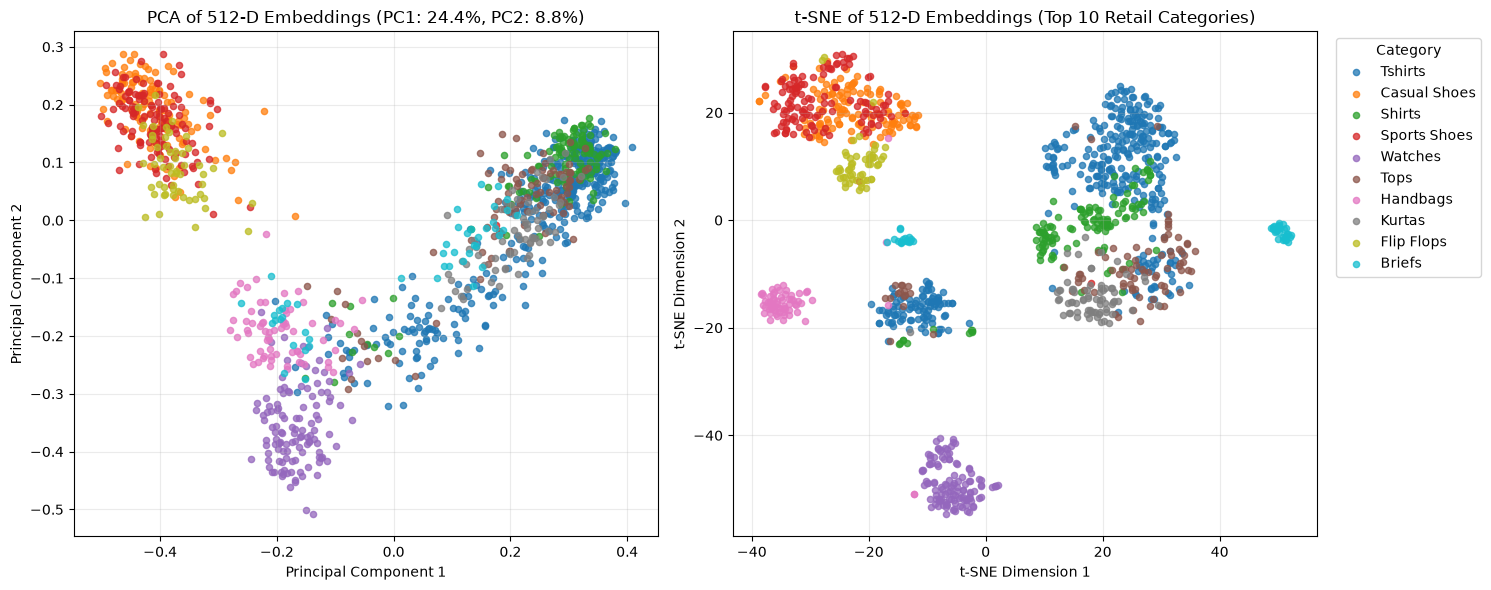

Saved PCA & t-SNE plot to reports/visualizations/pca_tsne_embeddings.png


In [40]:
pca = PCA(n_components=2, random_state=SEED)
emb_pca = pca.fit_transform(emb_sub)

tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto")
emb_tsne = tsne.fit_transform(emb_sub)

# 3. Plot Side-by-Side PCA & t-SNE
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmap = plt.get_cmap("tab10")

for idx_color, cls_id in enumerate(top10_classes):
    cls_mask = (labels_sub == cls_id)
    cls_name = idx_to_label[cls_id]
    axes[0].scatter(emb_pca[cls_mask, 0], emb_pca[cls_mask, 1], label=cls_name, alpha=0.75, s=20, color=cmap(idx_color))
    axes[1].scatter(emb_tsne[cls_mask, 0], emb_tsne[cls_mask, 1], label=cls_name, alpha=0.75, s=20, color=cmap(idx_color))

var_explained = pca.explained_variance_ratio_ * 100
axes[0].set_title(f"PCA of 512-D Embeddings (PC1: {var_explained[0]:.1f}%, PC2: {var_explained[1]:.1f}%)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(alpha=0.25)

axes[1].set_title("t-SNE of 512-D Embeddings (Top 10 Retail Categories)")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Category")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "visualizations" / "pca_tsne_embeddings.png", dpi=150)
plt.show()
print("Saved PCA & t-SNE plot to reports/visualizations/pca_tsne_embeddings.png")

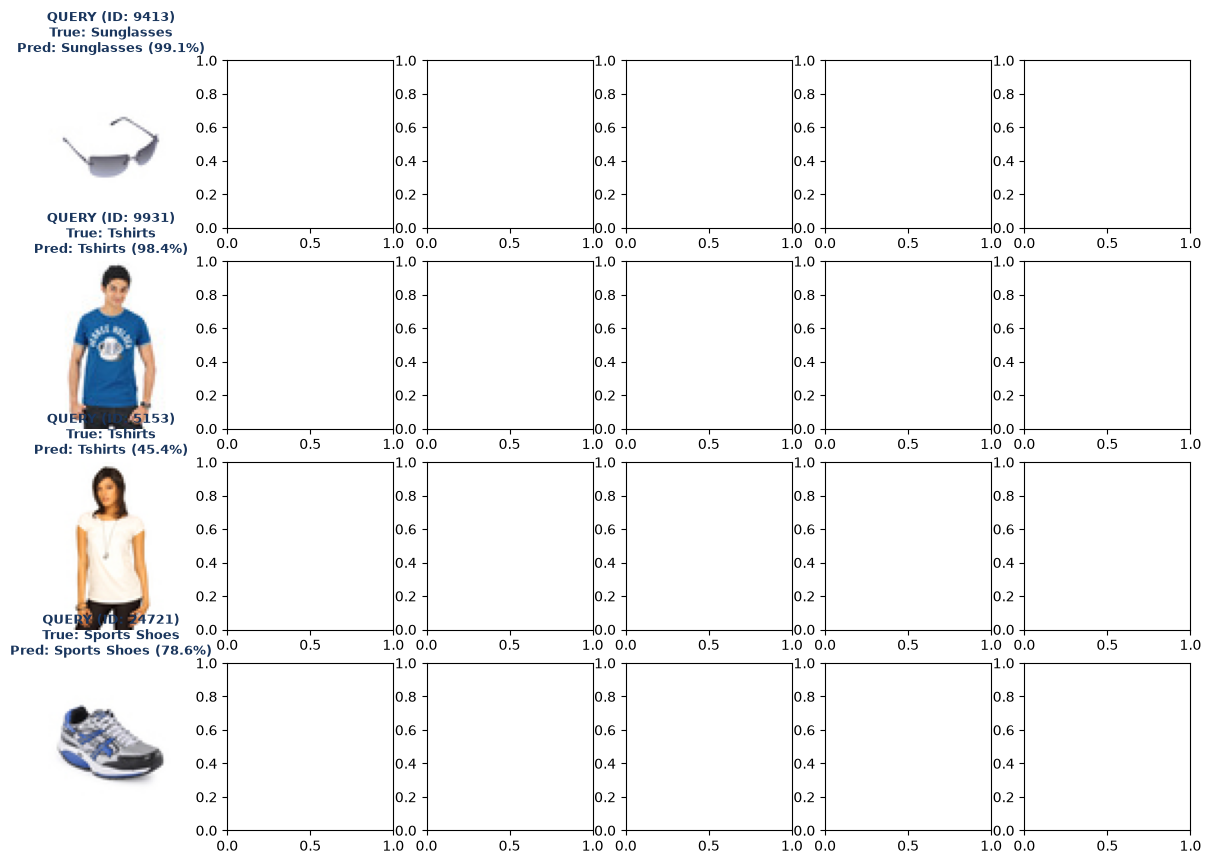

In [41]:
sample_query_positions = [0, 25, 80, 150]  # 4 fixed test query indices
fig, axes = plt.subplots(len(sample_query_positions), 6, figsize=(15, 10))

for row_i, q_pos in enumerate(sample_query_positions):
    q_row = test_df.iloc[q_pos]
    q_id  = q_row["id"]
    q_true_cat = q_row["articleType"]
    q_pred_cat = idx_to_label[int(test_preds[q_pos])]
    q_conf     = float(np.max(test_probs[q_pos])) * 100

    # Plot Query Image in Column 0
    with Image.open(IMG_DIR / f"{q_id}.jpg") as q_img:
        axes[row_i, 0].imshow(q_img.convert("RGB"))
    axes[row_i, 0].set_title(f"QUERY (ID: {q_id})\nTrue: {q_true_cat}\nPred: {q_pred_cat} ({q_conf:.1f}%)", fontsize=9, fontweight="bold", color="#1a365d")
    axes[row_i, 0].axis("off")

In [44]:
cos_sims = np.dot(cat_emb_e1, test_emb_e1[q_pos])
top5_cat_indices = e1_top5_indices[q_pos]

for rank_j, cat_idx in enumerate(top5_cat_indices):
        cat_row = train_df.iloc[cat_idx]
        cat_id  = cat_row["id"]
        cat_cat = cat_row["articleType"]
        sim_val = cos_sims[cat_idx]
        is_match = (cat_cat == q_true_cat)

        ax = axes[row_i, rank_j + 1]
        with Image.open(IMG_DIR / f"{cat_id}.jpg") as c_img:
            ax.imshow(c_img.convert("RGB"))
        border_color = "#2e7d32" if is_match else "#c62828"
        match_tag = "MATCH" if is_match else "DIFF"
        ax.set_title(f"Rank #{rank_j+1} ({match_tag})\n{cat_cat}\ncos={sim_val:.3f}", fontsize=8.5, color=border_color)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(2.5)

plt.suptitle("Phase I Visual Search Retrieval: Unseen Query -> Predicted Category + Top-5 Cosine Nearest Catalog Items", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "visualizations" / "top5_retrieval_examples.png", dpi=150)
plt.show()

exp_df = pd.read_csv(EXP_CSV_PATH)
print("\n=== MASTER EXPERIMENT COMPARISON TABLE (reports/experiment_comparison.csv) ===")
display(exp_df)

<Figure size 640x480 with 0 Axes>


=== MASTER EXPERIMENT COMPARISON TABLE (reports/experiment_comparison.csv) ===


,experiment_id,checkpoint,split,accuracy,macro_f1,precision_at_5,recall_at_5,map,query_latency_ms,index_size_mb,notes
0,E0_majority_baseline,None (Rule-based majority),test,0.1906,0.0063,NaN,NaN,NaN,NaN,NaN,Always predicts majority class (Tshirts); high...
1,E1_pretrained_resnet18_retrieval,ImageNet1K_ResNet18_Default,test,NaN,NaN,0.7654,0.0084,0.7226,0.2116,40.83,Off-the-shelf 512-D ImageNet features before r...
2,E2_frozen_backbone_classifier,models/e2_frozen_resnet18.pth,test,0.8175,0.7467,0.8175,0.0089,0.8175,0.3035,40.83,"Frozen ResNet-18 + Linear(512,51) trained w/ C..."
